# Лабораторная работа №1. Многослойный перцептрон
## Примет ли водитель купон на кафе или ресторан?
**Цель:** изучить обучение MLP, переобучение, влияние глубины и ширины, градиенты и функции активации. Задача — бинарная классификация: `Y=1` означает согласие принять купон, `Y=0` — отказ.

Источник: [UCI In-Vehicle Coupon Recommendation](https://archive.ics.uci.edu/dataset/603/in%2Bvehicle%2Bcoupon%2Brecommendation), [DOI: 10.24432/C5GS4P](https://doi.org/10.24432/C5GS4P). Лицензия **CC BY 4.0**. Данные получены через опрос Amazon Mechanical Turk: ответы описывают намерение в заданном сценарии, а не подтверждённые покупки. Работа-источник: Wang et al., *A Bayesian framework for learning rule sets for interpretable classification*, JMLR 18 (2017), 2357–2393.

Это внешний нишевый табличный датасет, а не встроенный учебный набор библиотеки. Интернет при запуске не требуется: CSV приложен. Все выводы ниже основаны на вычислениях.

## 0. Окружение и воспроизводимость
Запускать из корня проекта. Инструкция создания независимого окружения приведена в README. Текущее `.venv` использует доступные системные пакеты; их версии записаны в `requirements.txt`. Выбран CPU; фиксируются разбиение и генераторы случайных чисел. Время обучения зависит от компьютера.

In [1]:
from pathlib import Path
from dataclasses import dataclass, asdict
from copy import deepcopy
import random, time, json, hashlib, platform, importlib.metadata
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from torch import nn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, RocCurveDisplay)
from sklearn.dummy import DummyClassifier
from IPython.display import display, Markdown

@dataclass(frozen=True)
class Config:
    data_path: str = 'data/in-vehicle-coupon-recommendation.csv'
    result_dir: str = 'results'
    split_seed: int = 42
    seeds: tuple = (42, 43, 44)
    hidden: tuple = (64, 32)
    depths: tuple = (1, 2, 3)
    widths: tuple = (16, 64, 128)
    batch_size: int = 128
    epochs: int = 100
    patience: int = 15
    learning_rate: float = 0.001
    threshold: float = 0.5
    missing_limit: float = 0.95
    split_folds: int = 20
    train_folds: int = 14
    valid_folds: int = 3
    device: str = 'cpu'

cfg = Config()
assert 0 < cfg.train_folds < cfg.train_folds + cfg.valid_folds < cfg.split_folds
out = Path(cfg.result_dir); out.mkdir(exist_ok=True)
torch.set_num_threads(1)
torch.use_deterministic_algorithms(True)
sns.set_theme(style='whitegrid', context='notebook')
plt.rcParams.update({'figure.dpi': 110, 'axes.titlesize': 12})

def seed_everything(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)

def savefig(name):
    plt.savefig(out / name, bbox_inches='tight', dpi=140)
    plt.show()

versions = {p: importlib.metadata.version(p) for p in
            ['torch', 'numpy', 'pandas', 'scikit-learn', 'matplotlib', 'seaborn', 'nbformat', 'nbclient', 'jupyterlab', 'ipykernel']}
print('Python:', platform.python_version(), '| Устройство:', cfg.device)
display(pd.Series(versions, name='Версия').to_frame())
print(asdict(cfg))

Python: 3.13.7 | Устройство: cpu


,Версия
torch,2.8.0
numpy,2.3.3
pandas,2.3.3
scikit-learn,1.8.0
matplotlib,3.10.8
seaborn,0.13.2
nbformat,5.10.4
nbclient,0.10.4
jupyterlab,4.5.7
ipykernel,7.2.0


{'data_path': 'data/in-vehicle-coupon-recommendation.csv', 'result_dir': 'results', 'split_seed': 42, 'seeds': (42, 43, 44), 'hidden': (64, 32), 'depths': (1, 2, 3), 'widths': (16, 64, 128), 'batch_size': 128, 'epochs': 100, 'patience': 15, 'learning_rate': 0.001, 'threshold': 0.5, 'missing_limit': 0.95, 'split_folds': 20, 'train_folds': 14, 'valid_folds': 3, 'device': 'cpu'}


## 1. Загрузка и описание данных
В исходном файле 25 признаков: контекст поездки (`destination`, `passanger`, `weather`, `temperature`, `time`), предложение (`coupon`, `expiration`, время отклонения от маршрута), характеристики респондента и частота посещения заведений.

`age`, `income` и частоты посещений представлены интервалами/категориями: не предполагаем равные расстояния между ними и кодируем как категории. `temperature` — числовая температура в °F, бинарные индикаторы — числовые 0/1. Опечатка `passanger` сохранена из CSV. `car` описывает автомобиль и почти всегда отсутствует.

In [2]:
data_path = Path(cfg.data_path)
if not data_path.exists():
    raise FileNotFoundError(f'Нет {data_path.resolve()}. Скопируйте папку data из комплекта лабораторной.')
raw = pd.read_csv(data_path)
assert 'Y' in raw and set(raw.Y.unique()) == {0, 1}
print('SHA256:', hashlib.sha256(data_path.read_bytes()).hexdigest())
print('Исходная размерность:', raw.shape)
display(raw.head())
display(pd.DataFrame({'тип': raw.dtypes.astype(str), 'уникальных': raw.nunique(),
                      'пропусков': raw.isna().sum(), 'доля пропусков': raw.isna().mean()}))
duplicate_count = int(raw.duplicated().sum())
df = raw.drop_duplicates().reset_index(drop=True)
print(f'Удалено точных дубликатов: {duplicate_count}; осталось объектов: {len(df)}')
assert not df.duplicated().any()

SHA256: d47897367f5a12a31dece0f4e42d7bd9da76d7016b568da511b50335d08dcb43
Исходная размерность: (12684, 26)


,destination,passanger,weather,temperature,time,coupon,expiration,gender,age,maritalStatus,...,CoffeeHouse,CarryAway,RestaurantLessThan20,Restaurant20To50,toCoupon_GEQ5min,toCoupon_GEQ15min,toCoupon_GEQ25min,direction_same,direction_opp,Y
0,No Urgent Place,Alone,Sunny,55,2PM,Restaurant(<20),1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,1
1,No Urgent Place,Friend(s),Sunny,80,10AM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,0,0,0,1,0
2,No Urgent Place,Friend(s),Sunny,80,10AM,Carry out & Take away,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,1
3,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,2h,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0
4,No Urgent Place,Friend(s),Sunny,80,2PM,Coffee House,1d,Female,21,Unmarried partner,...,never,NaN,4~8,1~3,1,1,0,0,1,0


,тип,уникальных,пропусков,доля пропусков
destination,object,3,0,0.000000
passanger,object,4,0,0.000000
weather,object,3,0,0.000000
temperature,int64,3,0,0.000000
time,object,5,0,0.000000
coupon,object,5,0,0.000000
expiration,object,2,0,0.000000
gender,object,2,0,0.000000
age,object,8,0,0.000000
maritalStatus,object,5,0,0.000000


Удалено точных дубликатов: 74; осталось объектов: 12610


## 2. Первичный анализ
Графики полного набора описывают данные; выбор архитектуры далее использует только validation, а преобразования обучаются только на train. Доли согласия на графиках — наблюдаемые связи, не доказательство причинного влияния. При небольшом числе ответов в категории оценка менее надёжна.

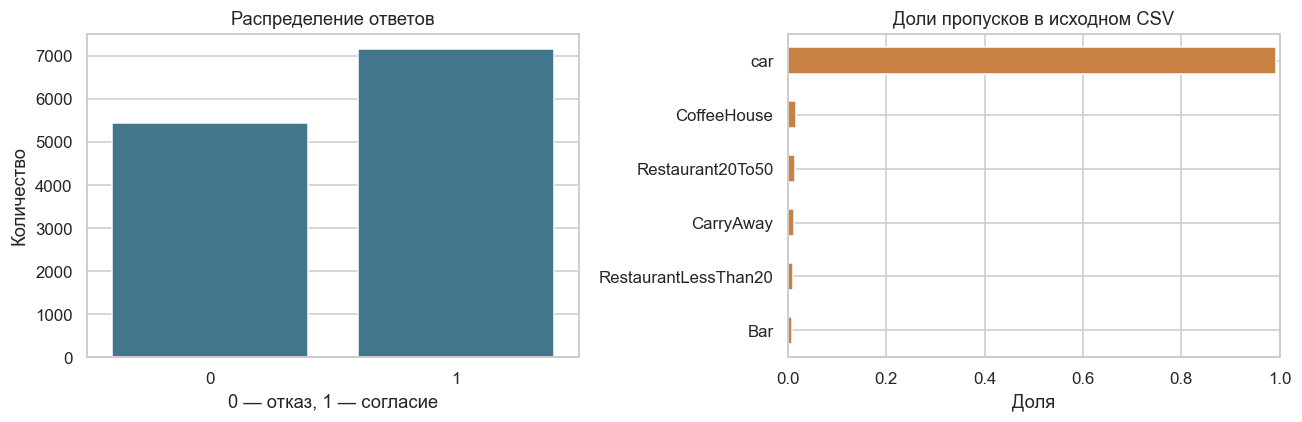

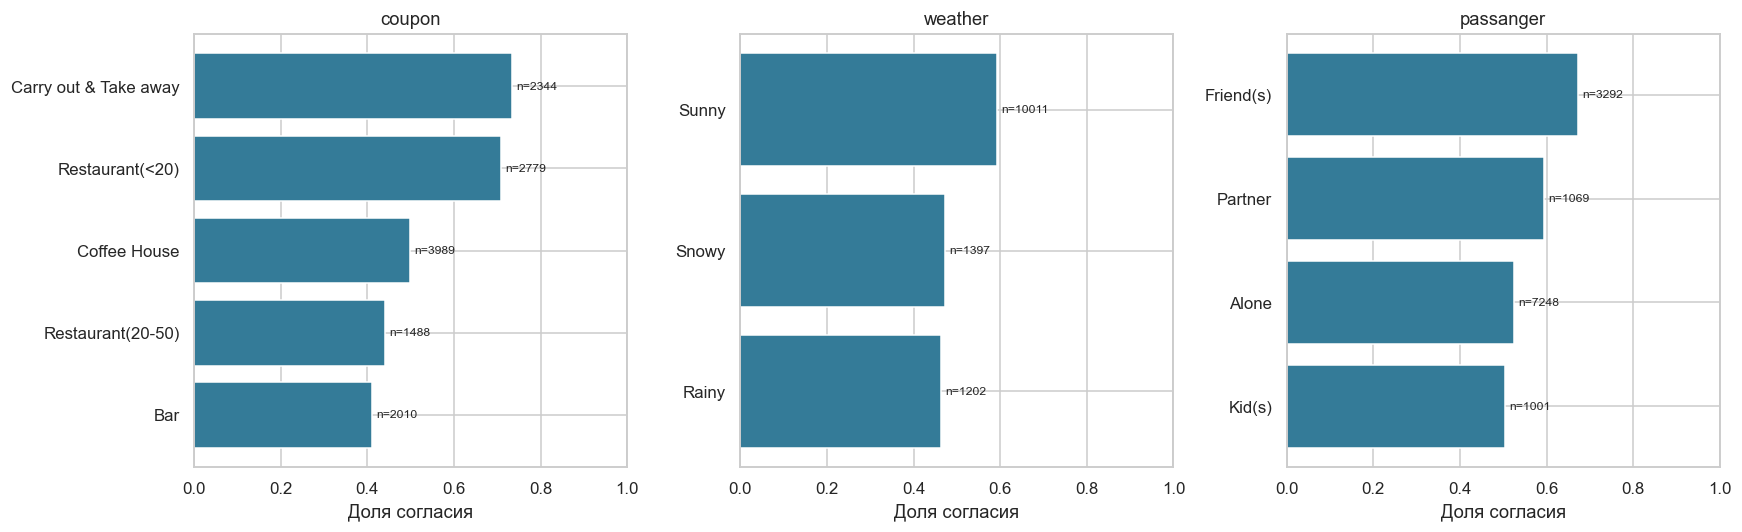

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
destination,12610,3,No Urgent Place,6266,NaN,NaN,NaN,NaN,NaN,NaN,NaN
passanger,12610,4,Alone,7248,NaN,NaN,NaN,NaN,NaN,NaN,NaN
weather,12610,3,Sunny,10011,NaN,NaN,NaN,NaN,NaN,NaN,NaN
temperature,12610.0,NaN,NaN,NaN,63.267248,19.153386,30.0,55.0,80.0,80.0,80.0
time,12610,5,6PM,3220,NaN,NaN,NaN,NaN,NaN,NaN,NaN
coupon,12610,5,Coffee House,3989,NaN,NaN,NaN,NaN,NaN,NaN,NaN
expiration,12610,2,1d,7031,NaN,NaN,NaN,NaN,NaN,NaN,NaN
gender,12610,2,Female,6469,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,12610,8,21,2642,NaN,NaN,NaN,NaN,NaN,NaN,NaN
maritalStatus,12610,5,Married partner,5068,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Доля положительного класса: 0.568; классы не равновероятны, но оба хорошо представлены.


In [3]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df, x='Y', ax=ax[0], color='#347b98')
ax[0].set(title='Распределение ответов', xlabel='0 — отказ, 1 — согласие', ylabel='Количество')
missing = raw.isna().mean().loc[lambda s: s > 0].sort_values()
missing.plot.barh(ax=ax[1], color='#c88043')
ax[1].set(title='Доли пропусков в исходном CSV', xlabel='Доля', xlim=(0, 1))
plt.tight_layout(); savefig('eda_quality.png')
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for col, ax in zip(['coupon', 'weather', 'passanger'], axes):
    summary = df.groupby(col).Y.agg(['mean', 'count']).sort_values('mean')
    ax.barh(summary.index, summary['mean'], color='#347b98')
    for i, (_, row) in enumerate(summary.iterrows()):
        ax.text(row['mean'] + .01, i, f"n={int(row['count'])}", va='center', fontsize=8)
    ax.set(title=col, xlabel='Доля согласия', xlim=(0, 1))
plt.tight_layout(); savefig('eda_acceptance.png')
display(df.describe(include='all').T)
print(f'Доля положительного класса: {df.Y.mean():.3f}; классы не равновероятны, но оба хорошо представлены.')

### Наблюдения по первичному анализу
Купоны на еду навынос и недорогие рестораны принимают чаще, чем предложения баров. С друзьями доля согласий выше, чем при поездках в одиночку или с детьми; в солнечную погоду — выше, чем в дождливую. Это описательные связи: одновременно могут различаться типы купонов, время поездки и состав участников. Категории неравны по объёму, поэтому рядом с долями показано число наблюдений.

В данных умеренный дисбаланс: положительный класс составляет примерно 57%. Простое предсказание согласия для всех объектов уже даёт заметный F1, поэтому обязательна проверка относительно константной модели. Столбец `car` почти полностью пуст; окончательное решение об удалении ниже принимается только по train. Частоты посещений также имеют пропуски, которые будут представлены отдельной категорией.

## 3. Train / validation / test и предобработка
**Train** используется для обучения весов и преобразований, **validation** — для ранней остановки и выбора архитектуры, **test** — только для финальной оценки после выбора.

Создаём 20 стратифицированных групповых фолдов, объединяем 14/3/3: примерно 70/15/15%. Группа — одинаковый набор исходных признаков без `Y`; противоположные ответы при одинаковых признаках остаются в одной выборке. Это предотвращает прямое повторение объектов между частями. Точные пропорции и баланс могут немного отличаться из-за группировки. Идентификаторов респондентов нет: независимость по людям гарантировать нельзя.

По **train** удаляем столбцы с более чем 95% пропусков и константы. Числовые пропуски заполняем медианой и стандартизуем; категориальные — строкой `__MISSING__`, затем one-hot. Неизвестные категории превращаются в нулевой блок. Категории и статистики validation/test не используются при fit.

In [17]:
X = df.drop(columns='Y'); y = df.Y.astype('int64')
groups = pd.util.hash_pandas_object(X, index=False).to_numpy()

splitter = StratifiedGroupKFold(n_splits=cfg.split_folds, shuffle=True, random_state=cfg.split_seed)
fold_id = np.full(len(df), -1, dtype=int)
for fold, (_, ids) in enumerate(splitter.split(X, y, groups)):
    fold_id[ids] = fold
indices = {
    'train': np.flatnonzero(fold_id < cfg.train_folds),
    'valid': np.flatnonzero((fold_id >= cfg.train_folds) & (fold_id < cfg.train_folds + cfg.valid_folds)),
    'test': np.flatnonzero(fold_id >= cfg.train_folds + cfg.valid_folds),
}

assert (fold_id >= 0).all()
for a, b in [('train', 'valid'), ('train', 'test'), ('valid', 'test')]:
    assert not set(indices[a]) & set(indices[b])
    assert not set(groups[indices[a]]) & set(groups[indices[b]])
assert sum(map(len, indices.values())) == len(df)

split_table = pd.DataFrame({k: {'n': len(ids), 'доля': len(ids)/len(df), 'доля Y=1': y.iloc[ids].mean()}
                           for k, ids in indices.items()}).T
display(split_table)

train_X = X.iloc[indices['train']]
drop_cols = train_X.columns[(train_X.isna().mean() > cfg.missing_limit) | (train_X.nunique(dropna=False) <= 1)].tolist()
keep_cols = train_X.columns.difference(drop_cols, sort=False).tolist()
numeric_cols = train_X[keep_cols].select_dtypes(include='number').columns.tolist()
category_cols = [c for c in keep_cols if c not in numeric_cols]
preprocessor = ColumnTransformer([
    ('numeric', Pipeline([('imputer', SimpleImputer(strategy='median')), ('scale', StandardScaler())]), numeric_cols),
    ('category', Pipeline([('imputer', SimpleImputer(strategy='constant', fill_value='__MISSING__')),
                          ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), category_cols),
])
preprocessor.fit(train_X)

arrays = {k: preprocessor.transform(X.iloc[ids]).astype(np.float32) for k, ids in indices.items()}
labels = {k: y.iloc[ids].to_numpy(dtype=np.float32) for k, ids in indices.items()}

input_dim = arrays['train'].shape[1]
assert 0 < input_dim < 1024
assert all(np.isfinite(a).all() and a.shape[1] == input_dim for a in arrays.values())
assert all(set(v) == {0., 1.} for v in labels.values())
print('Удалены по train:', drop_cols)
print('Числовые:', numeric_cols, '\nКатегориальные:', category_cols)
print('Размер входа после кодирования:', input_dim, '< 1024')
tensors = {k: (torch.from_numpy(arrays[k]).to(cfg.device), torch.from_numpy(labels[k]).to(cfg.device)) for k in arrays}
pd.DataFrame({'row': np.arange(len(df)), 'fold': fold_id}).to_csv(out / 'split.csv', index=False)

[ 8802935719092455587  8705125165977337669 18422986760932943241 ...
  7186688706835051048  7563962007397602402  2135341733246521418]


,n,доля,доля Y=1
train,8829.0,0.700159,0.567561
valid,1890.0,0.149881,0.567196
test,1891.0,0.149960,0.567953


Удалены по train: ['car', 'toCoupon_GEQ5min']
Числовые: ['temperature', 'has_children', 'toCoupon_GEQ15min', 'toCoupon_GEQ25min', 'direction_same', 'direction_opp'] 
Категориальные: ['destination', 'passanger', 'weather', 'time', 'coupon', 'expiration', 'gender', 'age', 'maritalStatus', 'education', 'occupation', 'income', 'Bar', 'CoffeeHouse', 'CarryAway', 'RestaurantLessThan20', 'Restaurant20To50']
Размер входа после кодирования: 113 < 1024


## 4. Базовая MLP: обучение, валидация и переобучение
Модель возвращает **логит**, поэтому Sigmoid не включён в последний слой: `BCEWithLogitsLoss` уже содержит устойчивую комбинацию sigmoid и бинарной cross-entropy. Для метрик применяем sigmoid и порог 0.5. Softmax для единственного выхода не подходит.

Архитектура строится по списку скрытых размеров. Параметры Adam, ранней остановки и число эпох одинаковы для всех экспериментов. Сохраняются веса эпохи с минимальной validation loss; выбор архитектуры позже выполняется по validation F1 восстановленной модели. Метрики train/validation на каждой эпохе считаются после обновлений на полной соответствующей выборке в `eval()`.

Признак переобучения — дальнейшее снижение train loss при росте validation loss и разрыв качества. Разрыв сам по себе не является строгим доказательством; вывод делаем по совокупности кривых.

In [5]:
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_sizes, output_dim=1, activation=nn.ReLU):
        super().__init__()
        sizes = [input_dim, *hidden_sizes]
        layers = []
        for left, right in zip(sizes[:-1], sizes[1:]):
            layers.extend([nn.Linear(left, right), activation()])
        layers.append(nn.Linear(sizes[-1], output_dim))
        self.network = nn.Sequential(*layers)
    def forward(self, x):
        return self.network(x).squeeze(-1)

def metrics(y_true, probability, threshold=cfg.threshold):
    pred = probability >= threshold
    return {'accuracy': accuracy_score(y_true, pred),
            'precision': precision_score(y_true, pred, zero_division=0),
            'recall': recall_score(y_true, pred, zero_division=0),
            'f1': f1_score(y_true, pred, zero_division=0),
            'roc_auc': roc_auc_score(y_true, probability)}

@torch.no_grad()
def predict_probability(model, x):
    model.eval()
    return torch.sigmoid(model(x)).cpu().numpy()

def train_model(hidden_sizes, seed, data, config):
    seed_everything(seed)
    model = MLP(data['train'][0].shape[1], hidden_sizes).to(config.device)
    optimizer = torch.optim.Adam(model.parameters(), lr=config.learning_rate)
    loss_fn = nn.BCEWithLogitsLoss()
    history = []; best_loss = float('inf'); best_state = None; stale = 0
    start = time.perf_counter()
    for epoch in range(1, config.epochs + 1):
        model.train()
        train_x, train_y = data['train']
        for ids in torch.randperm(len(train_x), device=config.device).split(config.batch_size):
            optimizer.zero_grad(set_to_none=True)
            logits = model(train_x[ids])
            assert logits.shape == train_y[ids].shape
            loss = loss_fn(logits, train_y[ids])
            if not torch.isfinite(loss): raise RuntimeError('Loss не является конечным числом')
            loss.backward(); optimizer.step()
        model.eval(); row = {'epoch': epoch}
        with torch.no_grad():
            for split in ['train', 'valid']:
                xx, yy = data[split]; logits = model(xx)
                row[split + '_loss'] = loss_fn(logits, yy).item()
                row[split + '_f1'] = f1_score(yy.cpu().numpy(), torch.sigmoid(logits).cpu().numpy() >= config.threshold)
        history.append(row)
        if row['valid_loss'] < best_loss:
            best_loss = row['valid_loss']; best_state = deepcopy(model.state_dict()); best_epoch = epoch; stale = 0
        else:
            stale += 1
        if stale >= config.patience: break
    model.load_state_dict(best_state); model.eval()
    with torch.no_grad():
        restored_loss = loss_fn(model(data['valid'][0]), data['valid'][1]).item()
    assert np.isclose(restored_loss, best_loss, atol=1e-7)
    return {'model': model, 'history': pd.DataFrame(history), 'best_epoch': best_epoch,
            'seconds': time.perf_counter()-start, 'parameters': sum(p.numel() for p in model.parameters())}

# Только train и validation передаются в процедуру обучения.
training_data = {k: tensors[k] for k in ['train', 'valid']}
base = train_model(cfg.hidden, cfg.seeds[0], training_data, cfg)
base_valid = metrics(labels['valid'], predict_probability(base['model'], tensors['valid'][0]))
dummy = DummyClassifier(strategy='most_frequent').fit(arrays['train'], labels['train'])
dummy_valid = metrics(labels['valid'], dummy.predict_proba(arrays['valid'])[:, list(dummy.classes_).index(1)])
display(pd.DataFrame({'Постоянный прогноз': dummy_valid, 'Базовая MLP': base_valid}).T.round(4))
print(f"Лучшая эпоха: {base['best_epoch']}; выполнено эпох: {len(base['history'])}; параметров: {base['parameters']}")

,accuracy,precision,recall,f1,roc_auc
Постоянный прогноз,0.5672,0.5672,1.0000,0.7238,0.5000
Базовая MLP,0.7233,0.7489,0.7705,0.7595,0.7906


Лучшая эпоха: 10; выполнено эпох: 25; параметров: 9409


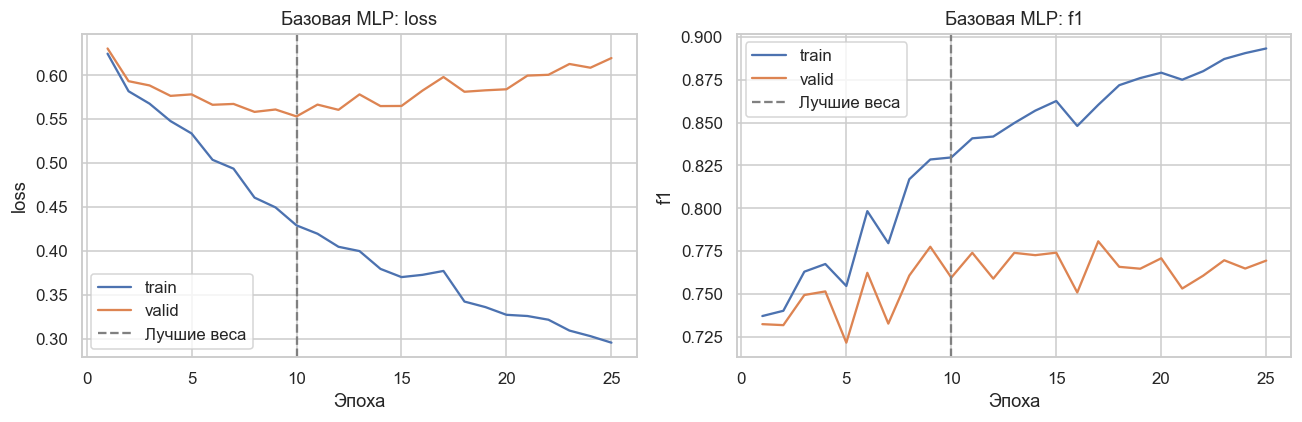

Лучшая эпоха — **10** из 25. На ней train F1=0.830, validation F1=0.760, разрыв=0.070. После неё train loss изменился 0.4290 → 0.2955, validation loss — 0.5531 → 0.6195. Наблюдается признак переобучения: train loss снизился, а validation loss вырос. Для дальнейшей оценки восстановлены веса лучшей эпохи, а не последней.

In [6]:
def plot_history(run, title, filename):
    h = run['history']; fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, metric in zip(axes, ['loss', 'f1']):
        for split in ['train', 'valid']: ax.plot(h.epoch, h[f'{split}_{metric}'], label=split)
        ax.axvline(run['best_epoch'], color='gray', linestyle='--', label='Лучшие веса')
        ax.set(xlabel='Эпоха', ylabel=metric, title=f'{title}: {metric}'); ax.legend()
    plt.tight_layout(); savefig(filename)

def overfit_report(run):
    h = run['history']; best = h.loc[h.epoch.eq(run['best_epoch'])].iloc[0]; last = h.iloc[-1]
    gap = best.train_f1 - best.valid_f1
    trend = last.train_loss < best.train_loss and last.valid_loss > best.valid_loss
    return (f"Лучшая эпоха — **{run['best_epoch']}** из {len(h)}. "
            f"На ней train F1={best.train_f1:.3f}, validation F1={best.valid_f1:.3f}, разрыв={gap:.3f}. "
            f"После неё train loss изменился {best.train_loss:.4f} → {last.train_loss:.4f}, "
            f"validation loss — {best.valid_loss:.4f} → {last.valid_loss:.4f}. "
            + ('Наблюдается признак переобучения: train loss снизился, а validation loss вырос. ' if trend else
               'По сравнению лучшей и последней эпох нет одновременного снижения train loss и роста validation loss; оцениваем также форму кривых. ')
            + 'Для дальнейшей оценки восстановлены веса лучшей эпохи, а не последней.')
plot_history(base, 'Базовая MLP', 'baseline_learning.png')
display(Markdown(overfit_report(base)))

## 5. Влияние глубины и ширины (+2 балла)
Сравниваем 9 равномерных архитектур (1/2/3 слоя × 16/64/128 нейронов) и базовую `[64, 32]`. Каждый вариант обучается с тремя seed на **неизменном разбиении**. Это 30 запусков; ранее обученная базовая сеть seed=42 используется повторно.

Среднее и выборочное стандартное отклонение характеризуют влияние инициализации и порядка батчей, а не неопределённость по всем возможным разбиениям. Победитель выбирается по среднему validation F1, при равенстве — по меньшему числу параметров. Для финальной оценки обеих моделей заранее фиксируем seed=42, не выбирая удачный запуск. Test не участвует в выборе.

Завершено: baseline, [64, 32], 3 запуска
Завершено: d1_w16, [16], 3 запуска
Завершено: d1_w64, [64], 3 запуска
Завершено: d1_w128, [128], 3 запуска
Завершено: d2_w16, [16, 16], 3 запуска
Завершено: d2_w64, [64, 64], 3 запуска
Завершено: d2_w128, [128, 128], 3 запуска
Завершено: d3_w16, [16, 16, 16], 3 запуска
Завершено: d3_w64, [64, 64, 64], 3 запуска
Завершено: d3_w128, [128, 128, 128], 3 запуска


,f1_mean,f1_std,auc_mean,parameters,seconds_mean,train_f1_mean,best_epoch_mean
architecture,,,,,,,
d1_w128,0.7818,0.0046,0.8092,14721,0.5915,0.8544,19.6667
d1_w64,0.7785,0.0026,0.8029,7361,0.6410,0.8452,26.6667
d1_w16,0.7722,0.0045,0.7869,1841,0.9520,0.8175,50.6667
baseline,0.7698,0.0094,0.7952,9409,0.4893,0.8304,10.0000
d2_w64,0.7618,0.0044,0.7902,11521,0.4762,0.8315,9.3333
d2_w16,0.7615,0.0084,0.7828,2113,0.7841,0.8092,27.3333
d3_w16,0.7591,0.0059,0.7797,2385,0.7413,0.8044,20.6667
d3_w64,0.7584,0.0105,0.7868,15681,0.4915,0.8223,6.6667
d2_w128,0.7583,0.0165,0.7895,31233,0.4619,0.8240,5.3333


Выбрана архитектура: d1_w128 (128,)


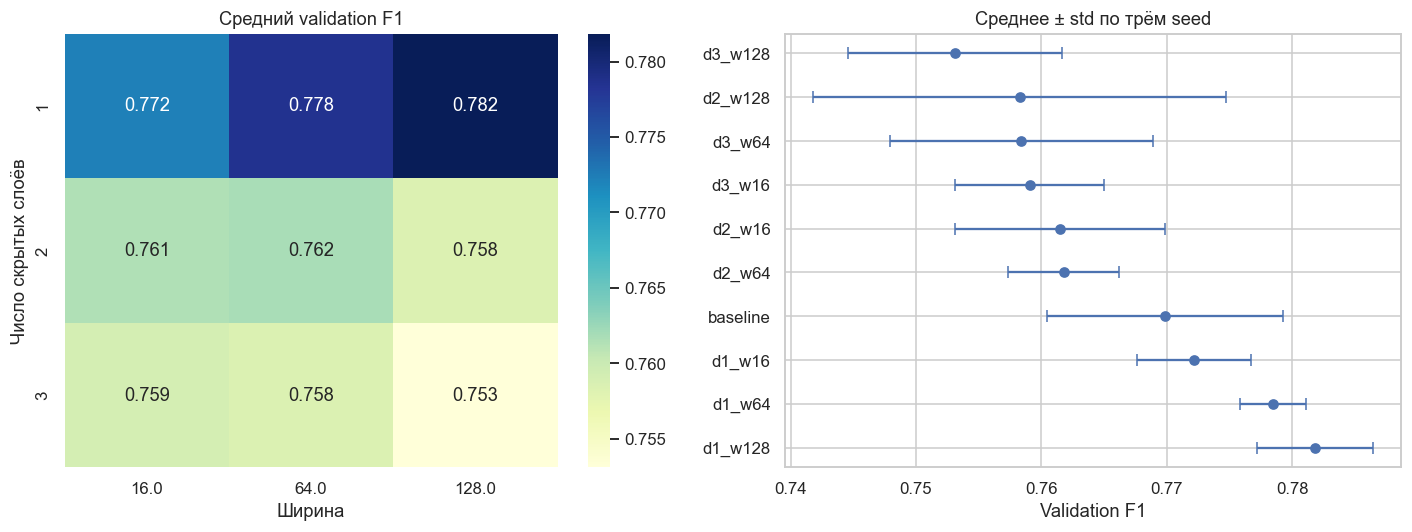

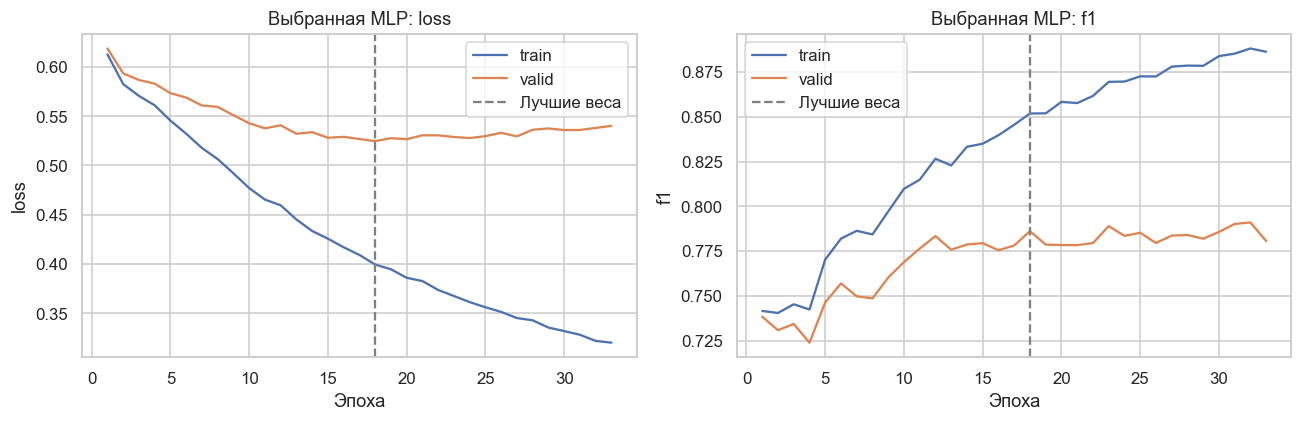

Лучшая эпоха — **18** из 33. На ней train F1=0.852, validation F1=0.786, разрыв=0.066. После неё train loss изменился 0.3993 → 0.3200, validation loss — 0.5247 → 0.5402. Наблюдается признак переобучения: train loss снизился, а validation loss вырос. Для дальнейшей оценки восстановлены веса лучшей эпохи, а не последней.

In [7]:
architectures = {'baseline': cfg.hidden}
architectures.update({f'd{d}_w{w}': (w,) * d for d in cfg.depths for w in cfg.widths})
runs = {}; records = []
for name, hidden in architectures.items():
    for seed in cfg.seeds:
        run = base if name == 'baseline' and seed == cfg.seeds[0] else train_model(hidden, seed, training_data, cfg)
        runs[name, seed] = run
        scores = metrics(labels['valid'], predict_probability(run['model'], tensors['valid'][0]))
        train_scores = metrics(labels['train'], predict_probability(run['model'], tensors['train'][0]))
        records.append({'architecture': name, 'hidden': str(list(hidden)), 'depth': len(hidden),
                        'width': hidden[0] if len(set(hidden)) == 1 else np.nan,
                        'seed': seed, 'parameters': run['parameters'], 'seconds': run['seconds'],
                        'best_epoch': run['best_epoch'], 'epochs': len(run['history']),
                        'train_f1': train_scores['f1'], **{f'valid_{k}': v for k,v in scores.items()}})
    print(f"Завершено: {name}, {list(hidden)}, {len(cfg.seeds)} запуска", flush=True)
results = pd.DataFrame(records)
summary = results.groupby('architecture').agg(
    f1_mean=('valid_f1','mean'), f1_std=('valid_f1','std'),
    auc_mean=('valid_roc_auc','mean'), parameters=('parameters','first'),
    seconds_mean=('seconds','mean'), train_f1_mean=('train_f1','mean'),
    best_epoch_mean=('best_epoch','mean')).sort_values(['f1_mean','parameters'], ascending=[False, True])
winner_name = summary.index[0]; winner = runs[winner_name, cfg.seeds[0]]
display(summary.round(4))
print('Выбрана архитектура:', winner_name, architectures[winner_name])
results.to_csv(out / 'architecture_runs.csv', index=False)
summary.to_csv(out / 'architecture_summary.csv')
for (name, seed), run in runs.items(): run['history'].to_csv(out / f'history_{name}_{seed}.csv', index=False)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
grid = results[results.architecture.ne('baseline')].groupby(['depth','width']).valid_f1.mean().unstack()
sns.heatmap(grid, annot=True, fmt='.3f', cmap='YlGnBu', ax=axes[0])
axes[0].set(title='Средний validation F1', xlabel='Ширина', ylabel='Число скрытых слоёв')
axes[1].errorbar(summary.f1_mean, np.arange(len(summary)), xerr=summary.f1_std.fillna(0), fmt='o', capsize=4)
axes[1].set_yticks(np.arange(len(summary)), summary.index)
axes[1].set(title='Среднее ± std по трём seed', xlabel='Validation F1')
plt.tight_layout(); savefig('architecture_comparison.png')
plot_history(winner, 'Выбранная MLP', 'winner_learning.png')
display(Markdown(overfit_report(winner)))

### Финальная оценка на test
Архитектура и seed уже зафиксированы. Теперь получаем test-вероятности по одному разу для каждой уникальной модели; все таблицы и графики используют этот сохранённый результат. Accuracy измеряет долю верных ответов, precision — точность положительных предсказаний, recall — полноту обнаружения согласий, F1 — их гармоническое среднее, ROC-AUC — качество ранжирования по всем порогам. Константная модель нужна для проверки, что сеть извлекает полезную информацию.

,accuracy,precision,recall,f1,roc_auc
baseline,0.7403,0.7643,0.7849,0.7745,0.8083
d1_w128,0.7589,0.7562,0.8492,0.8000,0.8221
constant,0.5680,0.5680,1.0000,0.7245,0.5000


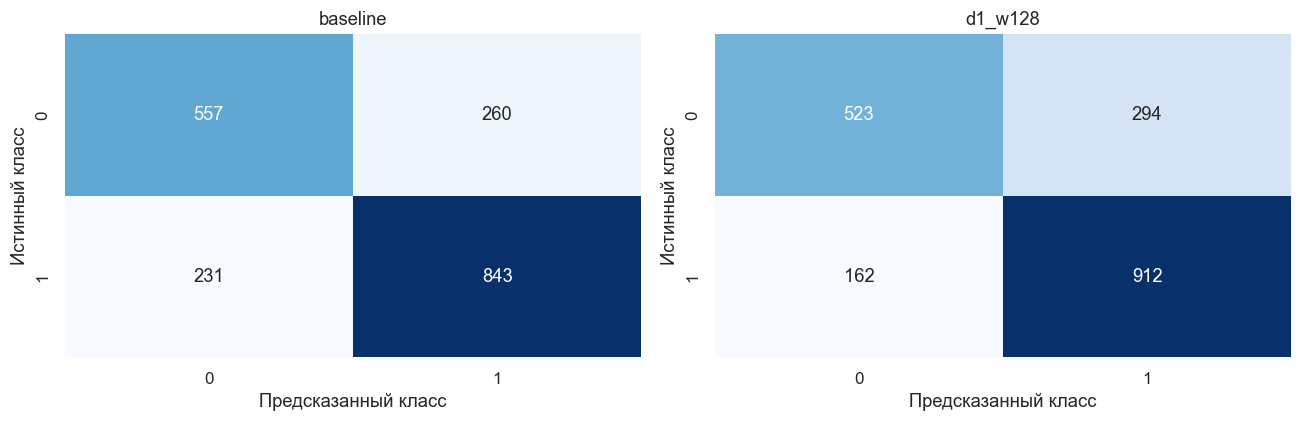

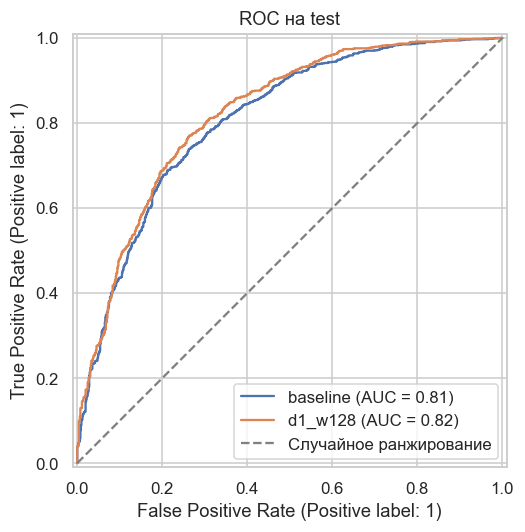

474

In [8]:
test_probability = {}
for name in dict.fromkeys(['baseline', winner_name]):
    test_probability[name] = predict_probability(runs[name, cfg.seeds[0]]['model'], tensors['test'][0])
dummy_test_probability = dummy.predict_proba(arrays['test'])[:, list(dummy.classes_).index(1)]
test_table = pd.DataFrame({**{name: metrics(labels['test'], p) for name,p in test_probability.items()},
                           'constant': metrics(labels['test'], dummy_test_probability)}).T
display(test_table.round(4)); test_table.to_csv(out / 'test_metrics.csv')
fig, axes = plt.subplots(1, len(test_probability), figsize=(6*len(test_probability), 4), squeeze=False)
for ax, (name,p) in zip(axes.flat, test_probability.items()):
    cm = confusion_matrix(labels['test'], p >= cfg.threshold, labels=[0,1])
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False, ax=ax)
    ax.set(title=name, xlabel='Предсказанный класс', ylabel='Истинный класс')
plt.tight_layout(); savefig('test_confusion.png')
fig, ax = plt.subplots(figsize=(6,5))
for name,p in test_probability.items(): RocCurveDisplay.from_predictions(labels['test'], p, name=name, ax=ax)
ax.plot([0,1],[0,1],'--',color='gray',label='Случайное ранжирование')
ax.set_title('ROC на test'); ax.legend(); plt.tight_layout(); savefig('test_roc.png')
np.savez(out / 'test_predictions.npz', y=labels['test'], **test_probability)
torch.save({'state_dict': winner['model'].state_dict(), 'input_dim': input_dim,
            'hidden_sizes': list(architectures[winner_name]), 'seed': cfg.seeds[0]}, out / 'best_model.pt')
import joblib
joblib.dump(preprocessor, out / 'preprocessor.joblib')
(out / 'config.json').write_text(json.dumps(asdict(cfg), indent=2, ensure_ascii=False), encoding='utf-8')

## 6. Градиенты при анализе одного объекта (+2 балла)
Берём первый объект **validation**. Дифференцируем скалярный логит класса 1 по входу, выходам каждого линейного слоя (до активации), весам и смещениям.

`eval()` переключает режим слоёв, но **не отключает autograd**. Для обычного инференса применяют `no_grad()`/`inference_mode()`; здесь они не подходят. Градиент логита характеризует локальную чувствительность решения, а не градиент ошибки обучения: метка объекта не используется. У ReLU градиент неактивных нейронов равен нулю. Нормы разных слоёв зависят от размерности и масштаба, поэтому их нельзя напрямую трактовать как глобальную важность.

,объект,форма,L2,max_abs,доля нулей
0,Вход,"(1, 113)",6.464844,2.358557,0.000000
1,network.0: выход,"(1, 128)",2.661990,0.618092,0.406250
2,network.2: выход,"(1, 1)",1.000000,1.000000,0.000000
3,network.0.weight,"(128, 113)",12.096832,0.729593,0.879148
4,network.0.bias,"(128,)",2.661990,0.618092,0.406250
5,network.2.weight,"(1, 128)",3.914490,1.254803,0.406250
6,network.2.bias,"(1,)",1.000000,1.000000,0.000000


Логит: -1.7811; вероятность: 0.1442; веса не изменены.


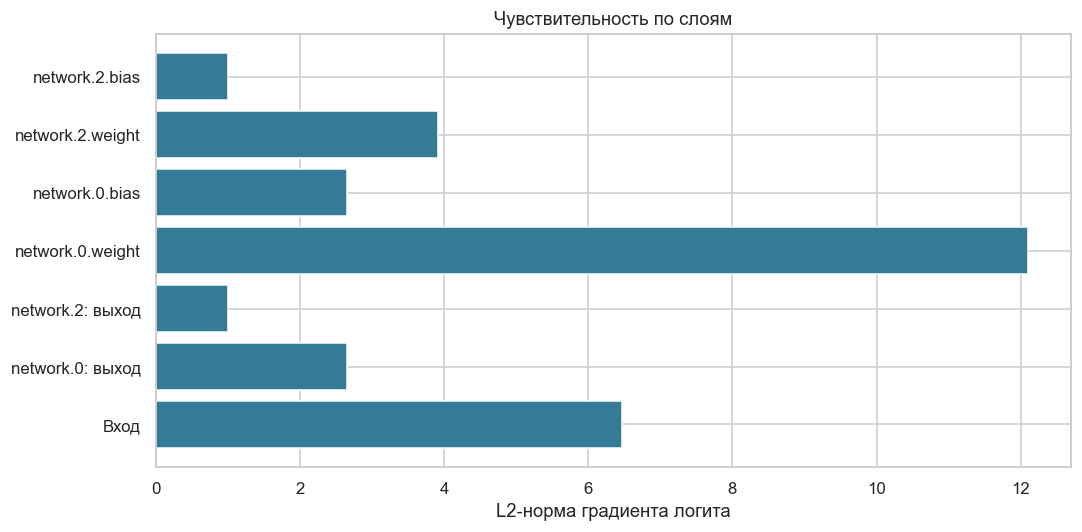

,Локальный градиент
category__coupon_Bar,-2.358557
category__education_Some High School,1.958638
category__Bar_1~3,1.610296
category__coupon_Carry out & Take away,1.545246
category__RestaurantLessThan20___MISSING__,1.371911
category__occupation_Installation Maintenance & Repair,-1.340836
category__Bar_never,-1.317729
category__occupation_Architecture & Engineering,1.279492
category__occupation_Healthcare Practitioners & Technical,1.193415
category__occupation_Construction & Extraction,1.145844


In [9]:
model = winner['model']; model.eval(); model.zero_grad(set_to_none=True)
before = {name: p.detach().clone() for name,p in model.named_parameters()}
activations = {}; handles = []
def capture(name):
    def hook(module, inputs, output):
        output.retain_grad(); activations[name] = output
    return hook
for name, layer in model.named_modules():
    if isinstance(layer, nn.Linear): handles.append(layer.register_forward_hook(capture(name)))
try:
    with torch.enable_grad():
        sample = tensors['valid'][0][:1].detach().clone().requires_grad_(True)
        logit = model(sample).sum(); logit.backward()
    rows = []
    def gradient_row(name, tensor):
        g = tensor.grad
        assert g is not None and torch.isfinite(g).all()
        return {'объект': name, 'форма': str(tuple(g.shape)), 'L2': g.norm().item(),
                'max_abs': g.abs().max().item(), 'доля нулей': (g == 0).float().mean().item()}
    rows.append(gradient_row('Вход', sample))
    for name, value in activations.items(): rows.append(gradient_row(name + ': выход', value))
    for name, value in model.named_parameters(): rows.append(gradient_row(name, value))
    gradients = pd.DataFrame(rows); display(gradients)
    assert all(torch.equal(before[name], p.detach()) for name,p in model.named_parameters())
    print(f'Логит: {logit.item():.4f}; вероятность: {torch.sigmoid(logit).item():.4f}; веса не изменены.')
    fig, ax = plt.subplots(figsize=(10,5))
    ax.barh(gradients['объект'], gradients.L2, color='#347b98')
    ax.set(xlabel='L2-норма градиента логита', title='Чувствительность по слоям')
    plt.tight_layout(); savefig('layer_gradients.png')
    feature_sensitivity = pd.Series(sample.grad[0].detach().cpu().numpy(),
                                    index=preprocessor.get_feature_names_out()).sort_values(key=abs, ascending=False)
    display(feature_sensitivity.head(10).rename('Локальный градиент').to_frame())
    gradients.to_csv(out / 'gradients.csv', index=False)
finally:
    for handle in handles: handle.remove()
    model.zero_grad(set_to_none=True)

## 7. Функции активации на NumPy (+1 балл)
| Функция | Свойства и применение |
|---|---|
| Identity | Без нелинейности; выход регрессии или логиты. Композиция только линейных слоёв остаётся аффинной. |
| Binary step | Порог 0: для x ≥ 0 возвращает 1. Непригодна для обычного градиентного обучения. |
| Sigmoid | Диапазон (0,1), вероятности бинарного класса; насыщение на больших модулях входа. |
| Tanh | Диапазон (−1,1), центрирована около нуля; также насыщается. |
| ReLU | max(0,x), проста; отрицательная ветвь имеет нулевой градиент. |
| LeakyReLU | Сохраняет небольшой наклон на отрицательной ветви. |
| ELU | Гладкая отрицательная ветвь, стремящаяся к −alpha. |
| Softplus | Гладкое приближение ReLU, положительный выход. |
| Softsign | x/(1+abs(x)), плавное ограничение диапазона. |
| Softmax | Преобразует вектор логитов в распределение по взаимоисключающим классам. |

Softmax рассматривается отдельно: это векторная функция. Для устойчивости вычитаем максимальный логит; Softplus реализуем через `logaddexp`, sigmoid — через устойчивое логарифмическое выражение.

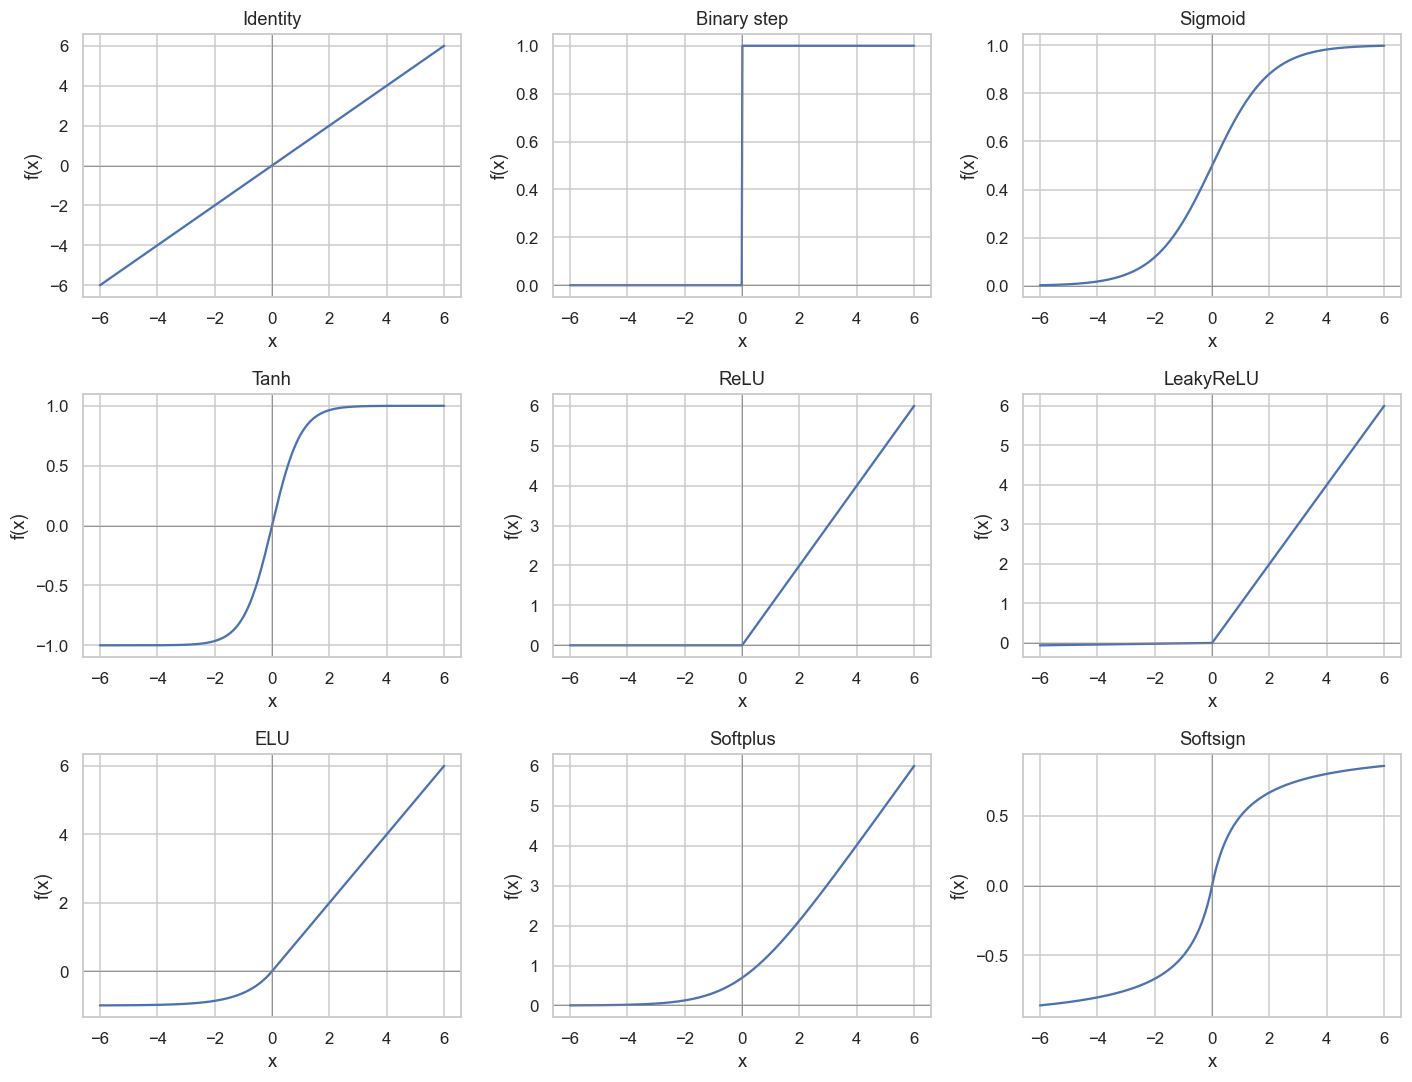

Логиты: [2.  1.  0.1] → Softmax: [0.65900114 0.24243297 0.09856589]


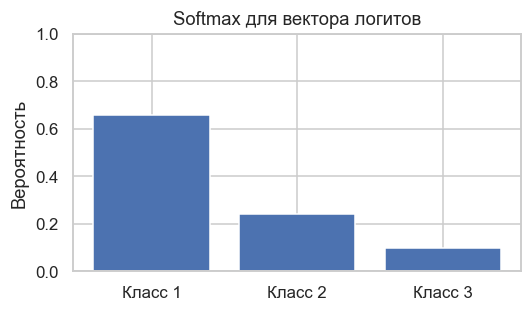

Проверки активаций пройдены.


In [10]:
def identity(x): return np.asarray(x, dtype=float)
def binary_step(x): return (np.asarray(x, dtype=float) >= 0).astype(float)
def sigmoid(x):
    x = np.asarray(x, dtype=float)
    return np.exp(-np.logaddexp(0., -x))
def tanh(x): return np.tanh(np.asarray(x, dtype=float))
def relu(x): return np.maximum(0., np.asarray(x, dtype=float))
def leaky_relu(x, alpha=0.01):
    x = np.asarray(x, dtype=float)
    return np.maximum(x, 0.) + alpha*np.minimum(x, 0.)
def elu(x, alpha=1.):
    x = np.asarray(x, dtype=float)
    return np.maximum(x, 0.) + alpha*np.expm1(np.minimum(x, 0.))
def softplus(x): return np.logaddexp(0., np.asarray(x, dtype=float))
def softsign(x):
    x = np.asarray(x, dtype=float)
    return x/(1+np.abs(x))
def softmax(x, axis=-1):
    x = np.asarray(x, dtype=float)
    shifted = x - np.max(x, axis=axis, keepdims=True)
    exp = np.exp(shifted)
    return exp/exp.sum(axis=axis, keepdims=True)

functions = {'Identity':identity, 'Binary step':binary_step, 'Sigmoid':sigmoid,
             'Tanh':tanh, 'ReLU':relu, 'LeakyReLU':leaky_relu, 'ELU':elu,
             'Softplus':softplus, 'Softsign':softsign}
x = np.linspace(-6,6,500)
fig, axes = plt.subplots(3,3,figsize=(13,10))
for ax,(name,fn) in zip(axes.flat,functions.items()):
    ax.plot(x,fn(x)); ax.axhline(0,color='gray',lw=.5); ax.axvline(0,color='gray',lw=.5)
    ax.set(title=name,xlabel='x',ylabel='f(x)')
plt.tight_layout(); savefig('activations.png')
example_logits = np.array([2.,1.,0.1])
print('Логиты:',example_logits, '→ Softmax:',softmax(example_logits))
fig, ax = plt.subplots(figsize=(5,3)); ax.bar(['Класс 1','Класс 2','Класс 3'],softmax(example_logits))
ax.set(ylabel='Вероятность',title='Softmax для вектора логитов',ylim=(0,1))
plt.tight_layout(); savefig('softmax.png')

# Контрольные точки и численная устойчивость.
assert np.allclose(identity([-1,0,1]),[-1,0,1])
assert np.array_equal(binary_step([-1,0,1]),[0,1,1])
assert np.allclose(sigmoid([0]),[.5]) and np.allclose(tanh([0]),[0])
assert np.allclose(relu([-1,0,1]),[0,0,1])
assert np.allclose(leaky_relu([-1,0,1]),[-.01,0,1])
assert np.allclose(elu([-1,0,1]),[np.expm1(-1),0,1])
assert np.allclose(softplus([0]),[np.log(2)])
assert np.allclose(softsign([-1,0,1]),[-.5,0,.5])
with np.errstate(over='raise', invalid='raise', divide='raise'):
    extreme = np.array([-1e4,0,1e4])
    for fn in functions.values(): assert np.isfinite(fn(extreme)).all()
    for values in [extreme, np.array([1e4,1e4,1e4]), np.array([-1e4,-1e4,-1e4])]:
        p = softmax(values)
        assert np.isfinite(p).all() and np.all(p >= 0) and np.isclose(p.sum(),1)
assert np.allclose(softmax(example_logits),softmax(example_logits+10000))
assert np.allclose(softmax(np.stack([example_logits,example_logits]),axis=1).sum(axis=1),1)
print('Проверки активаций пройдены.')

## 8. Итоги эксперимента и соответствие заданию

In [11]:
best_row = summary.loc[winner_name]; base_row = summary.loc['baseline']
wide = results[results.architecture.ne('baseline')].groupby(['depth','width']).valid_f1.mean().unstack()
depth_effect = (wide.loc[max(cfg.depths)] - wide.loc[min(cfg.depths)]).round(4).to_dict()
width_effect = (wide[max(cfg.widths)] - wide[min(cfg.widths)]).round(4).to_dict()
report = f"""
### Выводы по фактическим результатам
- После удаления **{duplicate_count}** дубликатов осталось **{len(df)}** объектов. После обработки вход имеет **{input_dim}** компонентов, что меньше 1024.
- Базовая MLP: validation F1 **{base_valid['f1']:.3f}**, константный прогноз: **{dummy_valid['f1']:.3f}**. Разница **{base_valid['f1']-dummy_valid['f1']:+.3f}**.
- По трём seed выбрана **{winner_name}**, скрытые слои **{list(architectures[winner_name])}**: validation F1 **{best_row.f1_mean:.3f} ± {best_row.f1_std:.3f}**. Базовая архитектура: **{base_row.f1_mean:.3f} ± {base_row.f1_std:.3f}**.
- Изменение среднего F1 при увеличении глубины с {min(cfg.depths)} до {max(cfg.depths)} (по ширинам): **{depth_effect}**. При увеличении ширины с {min(cfg.widths)} до {max(cfg.widths)} (по глубинам): **{width_effect}**. Рост размера не гарантирует улучшение: результат определяется также оптимизацией и переобучением.
- На test выбранная модель: F1 **{test_table.loc[winner_name,'f1']:.3f}**, ROC-AUC **{test_table.loc[winner_name,'roc_auc']:.3f}**; базовая: F1 **{test_table.loc['baseline','f1']:.3f}**; константная: F1 **{test_table.loc['constant','f1']:.3f}**. Test не использовался для подбора.
- {overfit_report(winner)}
- Градиенты получены для каждого линейного слоя без изменения весов; NumPy-активации проверены в контрольных точках и на больших входах.

**Ограничения:** один фиксированный split, только три seed; различия небольшого размера не доказывают статистическое превосходство. Многократный выбор по validation может завышать его оценку. Возможны повторные респонденты без идентификаторов; случайный split не оценивает перенос на новые популяции. Ответы опроса не эквивалентны реальным покупкам.
"""
display(Markdown(report))
(out / 'conclusions.md').write_text(report, encoding='utf-8')
assert len(results) == len(architectures)*len(cfg.seeds)
assert np.isfinite(results.select_dtypes('number').drop(columns='width').to_numpy()).all()
assert all(np.isfinite(r['history'].to_numpy()).all() for r in runs.values())
print('Все проверки: разбиение, размер входа, конечность обучения, восстановление весов, градиенты и активации — пройдены.')


### Выводы по фактическим результатам
- После удаления **74** дубликатов осталось **12610** объектов. После обработки вход имеет **113** компонентов, что меньше 1024.
- Базовая MLP: validation F1 **0.760**, константный прогноз: **0.724**. Разница **+0.036**.
- По трём seed выбрана **d1_w128**, скрытые слои **[128]**: validation F1 **0.782 ± 0.005**. Базовая архитектура: **0.770 ± 0.009**.
- Изменение среднего F1 при увеличении глубины с 1 до 3 (по ширинам): **{16.0: -0.0131, 64.0: -0.0201, 128.0: -0.0287}**. При увеличении ширины с 16 до 128 (по глубинам): **{1: 0.0096, 2: -0.0032, 3: -0.006}**. Рост размера не гарантирует улучшение: результат определяется также оптимизацией и переобучением.
- На test выбранная модель: F1 **0.800**, ROC-AUC **0.822**; базовая: F1 **0.774**; константная: F1 **0.724**. Test не использовался для подбора.
- Лучшая эпоха — **18** из 33. На ней train F1=0.852, validation F1=0.786, разрыв=0.066. После неё train loss изменился 0.3993 → 0.3200, validation loss — 0.5247 → 0.5402. Наблюдается признак переобучения: train loss снизился, а validation loss вырос. Для дальнейшей оценки восстановлены веса лучшей эпохи, а не последней.
- Градиенты получены для каждого линейного слоя без изменения весов; NumPy-активации проверены в контрольных точках и на больших входах.

**Ограничения:** один фиксированный split, только три seed; различия небольшого размера не доказывают статистическое превосходство. Многократный выбор по validation может завышать его оценку. Возможны повторные респонденты без идентификаторов; случайный split не оценивает перенос на новые популяции. Ответы опроса не эквивалентны реальным покупкам.


Все проверки: разбиение, размер входа, конечность обучения, восстановление весов, градиенты и активации — пройдены.


| Пункт задания | Реализация | Баллы по условию |
|---|---|---|
| 0 | Окружение, зависимости, инструкция запуска | В составе основы |
| 1 | Внешний нишевый датасет, менее 1024 компонентов на объект | В составе основы |
| 2 | Анализ типов, пропусков, классов и графики связей | В составе основы |
| 3 | Train/validation/test с объяснением и защитой от утечки | В составе основы |
| 4 | MLP, обучение, валидация, графики и проверка переобучения | Основа: 5 |
| 5 | Глубина × ширина, три seed и сравнение с базовой сетью | +2 |
| 6 | Градиенты входа, выходов и параметров каждого линейного слоя | +2 |
| 7 | NumPy-активации и их графики | +1 |

### Короткие ответы для защиты
1. **Почему три выборки?** Train обучает, validation помогает выбрать эпоху и архитектуру, test оценивает уже зафиксированное решение.
2. **Почему нельзя нормализовать до split?** Тогда статистики validation/test проникнут в обучение и сделают оценку менее независимой.
3. **Зачем группировать одинаковые признаки?** Чтобы одинаковые объекты не появлялись одновременно в обучении и оценке, в том числе с разными ответами.
4. **Как обнаружить переобучение?** Сопоставить кривые train и validation: улучшение train при ухудшении validation означает ухудшение обобщения. Early stopping сохраняет более ранние веса.
5. **Зачем нелинейные активации?** Без них последовательность линейных слоёв выражается одним аффинным преобразованием.
6. **Что меняют глубина и ширина?** Ёмкость, число параметров и сложность оптимизации; больше параметров не гарантирует лучшую проверочную метрику.
7. **Почему есть градиенты в eval?** `eval()` управляет поведением слоёв, а запись графа вычислений регулируется отдельно.
8. **Почему F1 и ROC-AUC?** F1 оценивает баланс precision/recall при фиксированном пороге; ROC-AUC — ранжирование независимо от одного порога.
9. **Почему не выбираем seed по test?** Это превратило бы test в ещё одну выборку для настройки и исказило итоговую оценку.
10. **Что сохраняется?** Таблицы и графики в `results`, веса `best_model.pt` и обученная предобработка `preprocessor.joblib`. Для нового объекта сначала применяют сохранённую предобработку, затем MLP и sigmoid.